# Notebook 1 Lab: Geometry and Perspective

This lab explores geometry and prespective through interactive code. The reusable function implementations live in `geometry.py` and you are invited to explore the code by yourself or assited by an llm to understand each implementation. Your job is to run experiments, change parameters, use your own photos, find failure cases, and explain what assumptions were used or violated.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Math, display

from geometry import (
    HIDDEN_AFFINE_TARGET_PARAMS,
    apply_homography,
    camera_project,
    estimate_homography,
    estimate_horizon,
    estimate_vanishing_point,
    line_from_points,
    load_rectification_photo_pair,
    make_affine_transform,
    rectify_plane,
    warp_image,
)
from visualization_utils import (
    affine_homography_comparison_tool,
    affine_match_widget,
    affine_slider_params,
    checkerboard,
    load_image,
    matrix_latex,
    normalize_homography_for_display,
    plane_rectification_tool,
    projection_widget,
    show_jitter_diagnostic,
    show_rectification_baseline,
    show_rectification_jitter_experiment,
    show_rectification_photo_pair,
    show,
    vanishing_directions_click_tool,
    vanishing_point_repeat_click_tool,
)

plt.rcParams["figure.figsize"] = (6, 4)

## 1. Image Transformations: Affine vs Homography

In this first activity, explore how rotation, scale, translation, and shear change the matrix and impact the resulting transformation

This activity requires `ipywidgets`. If the widget controls do not appear, paste the error message into an LLM and ask it how to install and enable `ipywidgets` for your Python/Jupyter setup. A typical starting point is `pip install ipywidgets notebook`, but your environment may differ.

The fixed target is on the left. Your interactive result is on the right. First try to match the target using the rotation slider. Then manually set rotation to zero and use `shear_x`, `shear_y`, and scale to make a rotation-like effect. Two simple shears do not equal a perfect rotation by themselves; inspect the matrix numbers in the next cell to see what extra scaling or distortion appears.


Exploration missions:

- Can you make a grid look slanted while its parallel lines remain parallel?
- Can you visually imitate rotation with shears while keeping rotation at zero?
- Which visual properties survive affine transforms? Which survive homographies?

In [ ]:
img = checkerboard()
H_target = make_affine_transform(**HIDDEN_AFFINE_TARGET_PARAMS)
target_img = warp_image(img, H_target, output_shape=(320, 320))

In [ ]:
controls = affine_match_widget(img, target_img)

In [ ]:
slider_params = affine_slider_params(controls)
H_current = make_affine_transform(**slider_params)

display(Math(matrix_latex(H_target, "H_{target}")))
display(Math(matrix_latex(H_current, "H_{current}")))

## 2. Perspective Projection

The pinhole model maps 3D points to 2D image points by dividing by depth. This is why equal-size objects can have different image sizes.

The four thick vertical lines in the visualization represent poles with the same height in 3D. The two grey poles are placed at different depths, so they initially appear at different heights in the image.

Exploration missions:

- Can you adjust the camera so that the two grey poles appear approximately the same height in the image? Does this mean that they are at the same depth in 3D?
- What changes when focal length changes but 3D geometry stays fixed?
- What changes when the camera is pitched up or down?

When investigating one parameter, re-run the cell below first to reset all controls to their initial values. This makes it easier to isolate the effect of that parameter if a previous experiment has left the camera at an unusual angle.

In [ ]:
projection_controls = projection_widget()

## 3. Plane Rectification

A homography can rectify one flat plane, such as a poster, book cover, sign, whiteboard, or billboard. It cannot generally flatten an entire 3D scene.

This section uses `images/yonge-and-dundas.jpg`. Click the four corners of a planar object in order. After the fourth click, a rectified preview appears beside the original image. Drag any corner on the original image to refine the selection and update the rectification live.

After rectifying, compare two versions of the same homography matrix:

- `H_rect`: maps pixel coordinates in the original image to pixel coordinates in the rectified image.
- `H_rect^{[0,1]}`: maps normalized coordinates, where both images use x and y values from 0 to 1.

The two matrices represent the same geometric warp, but their numbers look different because they use different coordinate systems. What can you learn from each normalization? Which features are easier to see in pixel coordinates, and which are easier to see in normalized coordinates? Why might normalized coordinates make the projective part of the homography easier to inspect?

Exploration missions:

- Click the four corners clockwise. Then try counter-clockwise. Do both directions work? What point order is the code assuming?
- Keeping the same clockwise order, try beginning at each of the four different corners. Does the starting corner matter? How does it change the orientation of the rectified result?
- Try a crossing order, such as top-left, bottom-right, top-right, bottom-left. What happens to the rectification?
- Can you tell from the homography matrix alone whether the clicked four points form a valid quadrilateral, or whether they form a bow-tie/self-crossing pattern? Try examples of both, compare the matrices, and consult an LLM if you want help designing a test.
- Rectify different billboards or posters. Can you find examples that violate the flat-plane assumption?
- Find billboards that only need an affine transform, and others that need a full homography. What matrix differences and visual differences tell you which case you are in?
- Try rectifying the entire image instead of one billboard. What assumptions break? Try using your own images

In [ ]:
%matplotlib widget
plane_state = plane_rectification_tool("yonge-and-dundas.jpg", figsize=(11, 5))

In [ ]:
if plane_state["H_rect"] is None:
    print("Click four corners in the previous cell first.")
else:
    H_rect = plane_state["H_rect"]
    H_rect_unit = normalize_homography_for_display(
        H_rect,
        plane_state["image"].shape,
        plane_state["rectified"].shape,
    )
    display(Math(matrix_latex(H_rect, "H_{rect}")))
    display(Math(matrix_latex(H_rect_unit, "H_{rect}^{[0,1]}")))


## 4. Invertibility and Backward Mapping

**Important: Before continuing, restart the notebook kernel and rerun ONLY the first import/setup cell. Do not rerun the earlier `%matplotlib widget` cell; otherwise, the output in this section may not display.**

A warp maps source image coordinates to destination image coordinates. There are two natural ways to implement this:

- **Forward mapping:** send each source pixel to a destination location.
- **Backward mapping:** visit each destination pixel and ask where it came from in the source.

In this section, use `images/mona-lisa.jpg` and compare the resulting images both visually and numerically. First inspect the displayed images. Then inspect the arrays behind them. What do you notice, and how does it relate to the implementation?

Exploration missions:

- What visual differences do you notice between the two mapped images?
- What numerical differences do you notice in their arrays?
- Where in the code might those numerical differences come from?
- Can you implement a small change that makes the forward-mapped result appear brighter rather than darker? What did you change, and why did it work?

In [ ]:
mona = load_image("mona-lisa.jpg")

fig, ax = plt.subplots(figsize=(4, 3))
show(mona, "Mona Lisa source image", ax);

In [ ]:
def forward_warp_points(image, H, output_shape):
    out = np.zeros((output_shape[0], output_shape[1], *image.shape[2:]), dtype=image.dtype)
    yy, xx = np.indices(image.shape[:2])
    src_points = np.column_stack([xx.ravel(), yy.ravel()])
    dst_points = apply_homography(H, src_points)
    x = np.rint(dst_points[:, 0]).astype(int)
    y = np.rint(dst_points[:, 1]).astype(int)
    valid = (0 <= x) & (x < output_shape[1]) & (0 <= y) & (y < output_shape[0])
    out[y[valid], x[valid]] = image.reshape(-1, *image.shape[2:])[valid]
    return out

H_expand_rotate = make_affine_transform(scale=(1.8, 1.45), rotation_degrees=-18, shear=(0.12, 0.0), translation=(-300, 600))
output_shape = (int(mona.shape[0] * 1.7), int(mona.shape[1] * 1.7))

forward = forward_warp_points(mona, H_expand_rotate, output_shape)
backward = warp_image(mona, H_expand_rotate, output_shape=output_shape)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
show(forward, "Forward mapping", ax[0])
show(backward, "Backward mapping", ax[1]);

## 5. Vanishing Points and Horizon

Parallel 3D lines may meet in the image. A set of image lines that correspond to the same 3D parallel direction should meet at one vanishing point. Two vanishing points for horizontal world directions define the horizon line.

Use `images/taormina.jpg`. For each vanishing point, click two endpoints per image line. Add at least two lines for Vanishing point A, then at least two lines for Vanishing point B.


After the tool estimates both vanishing points, the horizon line is stored as:

```python
h = vp_state["horizon"]  # [a, b, c]
```

These are homogeneous line coordinates. The image line equation is:

$$
a x + b y + c = 0.
$$

Exploration missions:

- Which edges seem to belong to the same 3D parallel direction?
- What happens if you mix lines from different directions under the same vanishing point?
- Does the vanishing point land inside or outside the image?
- Once both vanishing points are estimated, does the horizon line make visual sense?
- Was the picture taken with the camera parallel to the ground, or is the image slightly rotated?
- Can you estimate the image rotation using the horizon line (`h = vp_state["horizon"]`)? Write a function to do so.
- Which line would be horizontal if the camera were level?

In [ ]:
# For a fresh interactive canvas, restart the kernel, run only the import/setup cell at the top, and then run this cell. Do not run the intervening activity cells.
%matplotlib widget
image = load_image("taormina.jpg")
vp_state = vanishing_point_repeat_click_tool(image, figsize=(10, 7))

# Homework 1: Geometry

Homework 1 is worth **5.00 marks**.

| Task | Marks |
|---|---:|
| Task 1: Compare affine and projective rectification on your own photographs | 3.00 |
| Task 2: Estimate focal length from orthogonal vanishing points | 2.00 |
| **Total** | **5.00** |

## Task 1: Explore affine and homography rectification (3.00 marks)

Photograph the **same flat rectangular object** from two viewpoints. The object must have a known outer width-to-height ratio and a separate inner rectangle / inner border that will not be used to fit either transformation. This inner rectangle lets you evaluate geometry separately from the four fitted outer corners. A pair of example photos would be like below, where you have an inner rectangular region, aside for the outer rectangle border:

<div>
<img src="images/bookcover1.png" width="500"/>
</div>


<div>
<img src="images/bookcover2.png" width="500"/>
</div>

Create a folder named **`homework1_photos`** beside this notebook and use these exact filenames:

| Filename | Required viewpoint | Required visual evidence |
|---|---|---|
| `mild.jpg` | Nearly frontal or mildly oblique | All four outer corners and the held-out inner rectangle are visible; perspective convergence is small but not necessarily zero. |
| `strong.jpg` | Strongly oblique | All four outer corners remain visible; at least one pair of physically parallel edges visibly converges and the far side is noticeably foreshortened. |

### Capture controls

- Use the same planar object, camera, physical width, and physical height in both photographs.
- You should have a rough estimate of the object's aspect ratio (width and height irrespective of units).
- Begin each point set at the object's physical top-left corner and proceed clockwise: top-left, top-right, bottom-right, bottom-left.
- Use the standard camera application on default capture mode.
- Avoid faces, addresses, documents, screens, or other private information. 

The code uses all four outer correspondences for both models. The affine transform is therefore a least-squares fit, while the homography can fit four non-collinear correspondences exactly.
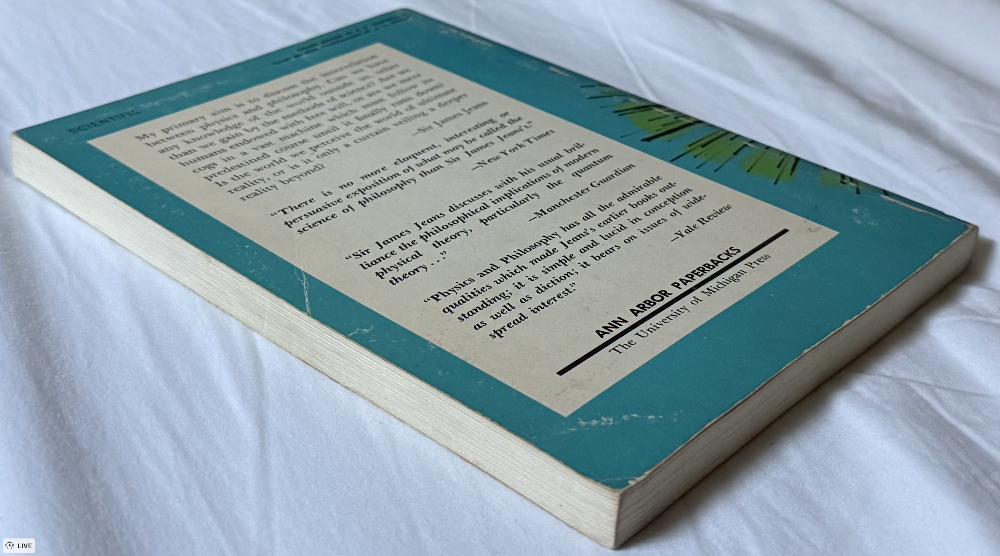
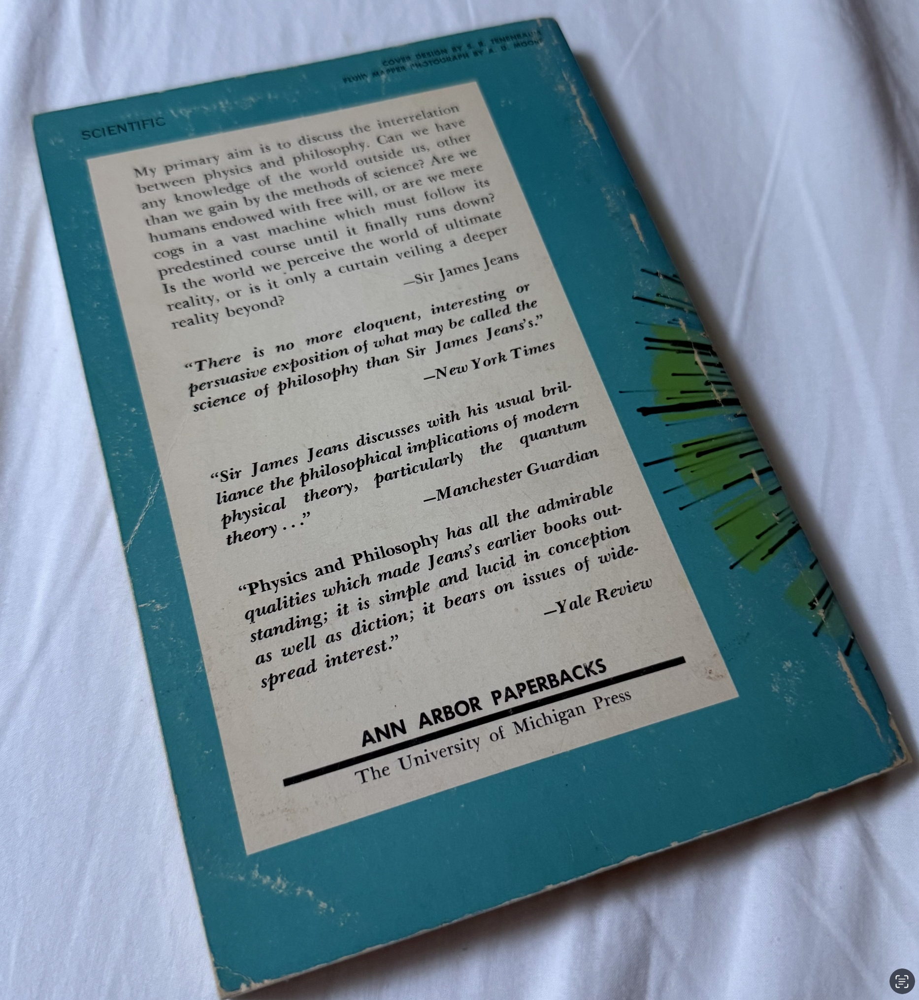

In [ ]:
# Replace both values with the measured outer dimensions of your object.
OBJECT_WIDTH = 16
OBJECT_HEIGHT = 24

homework1_photo_data = load_rectification_photo_pair(
    "homework1_photos",
    object_width=OBJECT_WIDTH,
    object_height=OBJECT_HEIGHT,
)
show_rectification_photo_pair(homework1_photo_data)

### Make a prediction before selecting points

Before continuing, you should think about the following poitns. Note that these are **not marked for correctness**.

1. In which photograph should the affine and homography results differ more? What visible evidence supports that prediction?
2. If the affine model leaves geometric distortion, where in the object or held-out rectangle do you expect it to be easiest to see?
3. Would the same absolute corner-selection error have the same effect in the mild and strongly oblique photographs? Which region might be most sensitive?

**If the following widget doesn't show up:** restart the kernel, run **only** the first import/setup cell, then run the Task 1 loading cell and the interactive cell below. Do not run the earlier `%matplotlib widget` activity cells before this canvas.

For each photograph, use the **Photo** and **Selecting** controls to collect:

- the four outer corners used for fitting, and
- the four corners of the held-out inner rectangle.

Select both sets **TOP-LEFT then CLOCKWISE**. 

In [ ]:
# One interactive canvas stores both photographs and both point sets.
%matplotlib widget
homework1_comparison_state = affine_homography_comparison_tool(
    homework1_photo_data["photos"],
    homework1_photo_data["aspect_ratio"],
    figsize=(12, 8), # Adjust this if the figure does fit on your screen
)

### Record the baseline comparison

After selecting all sixteen points, run the supplied cell below. It verifies that both photographs are complete, measures the transformed **held-out inner rectangle**, and creates a static comparison that remains visible after the next required kernel restart.

The cell reports two geometric metrics:

- **Right-angle error:** for each of the held-out rectangle's four corners, measure the angle between its two adjacent transformed edges and take $|\theta-90^\circ|$. The reported value is the mean of those four errors. For example, $5^\circ$ means that a transformed corner differs from a right angle by $5^\circ$ on average.
- **Parallel error:** measure the smaller angle between the directions of the transformed top and bottom edges, then between the left and right edges. The reported value is the mean of those two direction differences. For example, $5^\circ$ means that opposite sides differ in direction by $5^\circ$ on average rather than being parallel.

Both metrics are measured in degrees, an ideal rectangle has $0^\circ$ for both, and **lower is better**. They summarize held-out geometry only: they do not measure sharpness, interpolation artifacts, overall visual quality, or fitted outer-corner error.

In [ ]:
homework1_baseline_results = show_rectification_baseline(
    homework1_comparison_state
)

### 1.1 Corner jitter implementation [0.75 marks]

The next experiment should simulate uncertainty in the four outer corners used to fit each transformation. You will implement `jitter_points`, which adds random coordinate offsets to an input point set. 

For an input array with shape `(N, 2)`, your function must:

- return a **new** array with the same shape;
- add an independent sample from $\mathcal N(0,\sigma_{px}^2)$ to every x and y coordinate, using NumPy's `rng`;
- leave the input array unchanged;
- return the original coordinates when `sigma_px == 0`;
- reject a negative or non-finite `sigma_px` with `ValueError`.

The diagnostic cell will call your function hundreds of times. It displays the jittered quadrilaterals and the distribution of offsets around zero, then reports empirical means, standard deviations, and cross-coordinate correlations. Use these outputs to check your implementation before running the rectification experiment.

After the diagnostic passes, the supplied sensitivity experiment will use **your** `jitter_points` function to perturb only the outer fitting corners. It keeps the photo, aspect ratio, and held-out inner rectangle fixed, then refits both transformations. This isolates how outer-corner measurement uncertainty affects the rectified geometry.

> **1.1 Corner jitter implementation [0.75 marks].** Complete the function without changing its signature. 

In [ ]:
def jitter_points(points, sigma_px, rng):
    """Return a jittered copy of an (N, 2) point array."""
    points = np.asarray(points, dtype=float)
    sigma_px = float(sigma_px)

    # validate the inputs and add independent Gaussian coordinate noise.
    if points.ndim != 2 or points.shape[1] != 2:
        raise ValueError("points must have shape (N, 2).")

    if not np.all(np.isfinite(points)):
        raise ValueError("points must contain only finite coordinates.")

    if not np.isfinite(sigma_px) or sigma_px < 0:
        raise ValueError("sigma_px must be finite and non-negative.")

    noise = rng.normal(loc=0.0, scale=sigma_px, size=points.shape)
    jittered = points + noise

    return jittered

In [ ]:
JITTER_PREVIEW_SIGMA_PX = 8
JITTER_PREVIEW_TRIALS = 400

homework1_jitter_diagnostic = show_jitter_diagnostic(
    homework1_comparison_state,
    jitter_points,
    view_name="strong",
    sigma_px=JITTER_PREVIEW_SIGMA_PX,
    trials=JITTER_PREVIEW_TRIALS,
    seed=320,
    figsize=(9, 5), # Adjust this if the figure does fit on your screen
)

In [ ]:
CORNER_NOISE_LEVELS_PX = (0, 2, 5, 10)
CORNER_NOISE_TRIALS = 40

homework1_perturbation = show_rectification_jitter_experiment(
    homework1_comparison_state,
    jitter_points,
    noise_levels=CORNER_NOISE_LEVELS_PX,
    trials=CORNER_NOISE_TRIALS,
    seed=320,
    figsize=(9, 4.5), # Adjust this if the figure does fit on your screen
)
homework1_perturbation_trials = homework1_perturbation["trials"]
homework1_perturbation_summary = homework1_perturbation["summary"]

### Interpret the planar comparison (1.50 marks)

The following two questions are worth 1.50 marks. 
> **1.2 Viewpoint comparison [0.75 marks]**
>
> For **each of the two planar photographs**, discuss the differences between affine and homography rectification visually and also error-wise. Then explain how moving from the mild to the strong viewpoint changed the difference between the models. 

**1.2 Answer:**
*In the mild view, the two rectifications look broadly similar, but homography restores the inner rectangle more accurately, with lower right-angle and parallel errors (0.651﷿﷿ and 0.935﷿﷿) than affine rectification (2.624﷿﷿ and 3.249﷿﷿).
In the strong view, affine rectification leaves more noticeable perspective distortion, while homography produces a more rectangular result, reducing the respective errors from 7.046﷿﷿ and 9.012﷿﷿ to 0.906﷿﷿ and 0.454﷿﷿.
Thus, moving from the mild to the strong viewpoint increases the gap between the models because homography accounts for perspective distortion that an affine transformation cannot fully correct.*

> **1.3 Corner sensitivity [0.75 marks]**
>
> Discuss whether the same coordinate uncertainty had the same effect across models and viewpoints. Identify any result that did or did not match your initial expectation and give a plausible geometric or measurement-based explanation.

**1.3 Answer:**
*The same corner noise affected the two models differently. Overall, homography﷿﷿﷿s errors increased more with noise and showed greater variability, while affine medians remained fairly stable. This may be because homography fits the noisy corners exactly, whereas affine uses a least-squares fit with fewer degrees of freedom. Despite this greater sensitivity, homography retained lower median right-angle errors in both views.
As expected, affine rectification showed greater variability in the strong view: at 10 px noise, its IQR was 0.751﷿﷿, compared with 0.127﷿﷿ in the mild view. Stronger foreshortening can amplify corner-location errors during rectification, making the recovered angles more sensitive to the same pixel uncertainty.*

### 1.4 Homography failure case [0.75 marks]

Capture a new photo and name it **`failure.jpg`**. Save it in `homework1_photos` beside `mild.jpg` and `strong.jpg`.

Think of a scene or region where you expect a single homography to fail. Capture it yourself, then use the supplied cell below to select four points around the region you want to rectify. After the fourth click, the homography result appears on the right; drag a selected point if you need to correct an inaccurate click.

Note that the goal is to expose a limitation of the homography model, so a bad result caused by bad point selection does not count. 

**Fresh-canvas instruction:** finish and save the earlier Task 1 outputs, restart the kernel, and run **only** the first import/setup cell before running the cell below. Do not rerun the earlier `%matplotlib widget` cells.

In [ ]:
# Click four points around the region you want to rectify.
%matplotlib widget
failure_state = plane_rectification_tool(
    "failure.jpg",
    image_dir="homework1_photos",
    figsize=(11, 5), # Adjust this if the figure does fit on your screen
)

> **1.4 Homography failure case [0.75 marks]**
>
> Identify specific evidence in the rectified output that it failed. Explain which assumption of a single homography was violated and why changing only the corners cannot fix the complete result.

**1.4 Answer:** *In the rectified output, the definition-box borders and text lines near the spine remain curved. The page is physically curved, violating the assumption that the entire region lies on a single plane. Adjusting the corners changes the global homography but cannot remove the varying distortion within the page, so it cannot straighten all borders and text lines simultaneously.*

## Task 2: Estimate focal length from vanishing points (2.00 marks)

In this photo of a crossing in Taito (by: [Lala Azizli](https://unsplash.com/@lazizli)), the two visible faces of the Aoki building with orange banners provide two horizontal world directions. If the building corner is rectangular, those directions are perpendicular in 3D.

**After completing Task 1, restart the kernel and run only the first import/setup cell before running the single interactive Task 2 cell below. Do not rerun Task 1 or any earlier `%matplotlib widget` cells.** 

### 2.1 Lines selection [0.40 marks]

Use the **Selecting** buttons to switch between the two facade line groups without creating a new canvas. For every group, click two endpoints on each image line. Use at least four long, well-separated lines rather than relying on the minimum of two. Switching groups cancels an unfinished one-endpoint selection.

The combined state is saved as `taito_vanishing_state`. The aliases `taito_facade_a_state` and `taito_facade_b_state` refer to its live nested states. Each direction retains:

- `state["segments"]`: the clicked endpoint pairs
- `state["lines"]`: homogeneous image lines `[a, b, c]`
- `state["vanishing_point"]`: the fitted vanishing point in pixels

Use **Undo active line**, **Clear active**, or **Clear all** to correct selections. A vanishing point may correctly lie far outside the image; its coloured arrow shows the direction and its coordinates remain saved.

In [ ]:
# One canvas collects both facade vanishing directions.
%matplotlib widget
taito_image = load_image("taito.jpg")
taito_vanishing_state = vanishing_directions_click_tool(
    taito_image, figsize=(10, 7)
)

# These aliases point to live dictionaries that update whenever you click.
taito_facade_a_state = taito_vanishing_state["directions"]["facade_a"]
taito_facade_b_state = taito_vanishing_state["directions"]["facade_b"]

### Save the selected scene geometry

Run the next cell only after fitting both facade directions. The estimated horizon is shown in red on the canvas. The following code validates the selections and saves the vanishing points, horizon, image dimensions, and assumed principal point for later cells.

In [ ]:
taito_direction_states = {
    "facade_a": taito_facade_a_state,
    "facade_b": taito_facade_b_state,
}

missing = [
    name
    for name, state in taito_direction_states.items()
    if state["vanishing_point"] is None
]
if missing:
    raise RuntimeError(
        "Fit at least two lines for each missing direction: " + ", ".join(missing)
    )

taito_vp_a = taito_facade_a_state["vanishing_point"].copy()
taito_vp_b = taito_facade_b_state["vanishing_point"].copy()
taito_horizon = estimate_horizon(taito_vp_a, taito_vp_b)

taito_height, taito_width = taito_image.shape[:2]
taito_principal_point = np.array(
    [(taito_width - 1) / 2, (taito_height - 1) / 2], dtype=float
)

taito_geometry = {
    "image_shape": taito_image.shape,
    "principal_point": taito_principal_point,
    "vp_a": taito_vp_a,
    "vp_b": taito_vp_b,
    "horizon": taito_horizon,
    "direction_states": taito_direction_states,
}

print(f"VP A: {taito_vp_a}")
print(f"VP B: {taito_vp_b}")
print(f"Horizon [a, b, c]: {taito_horizon}")
print(f"Assumed principal point: {taito_principal_point}")

### Derive focal length from two vanishing points

Your task is to determine the focal length in millimetres ($f_{mm}$) of the lens used to take this image. First, you need to find the focal length in units of pixels ($f_{pixel}$).

Let the two horizontal vanishing points be written in homogeneous pixel coordinates as

$$
\tilde{\mathbf v}_A = [u_A, y_A, 1]^T, \qquad
\tilde{\mathbf v}_B = [u_B, y_B, 1]^T.
$$

Assume zero skew, square pixels, and a known principal point $\mathbf c=(c_x,c_y)$. The principal point is where the camera's optical axis intersects the image plane. The intrinsic calibration matrix is

$$
K = \begin{bmatrix}
f & 0 & c_x \\
0 & f & c_y \\
0 & 0 & 1
\end{bmatrix}.
$$

A vanishing point identifies the camera ray for its corresponding 3D direction:

$$
\mathbf r_i \propto K^{-1}\tilde{\mathbf v}_i.
$$

Find an expression for $f_{pixel}$ in terms of $u_A,u_B,y_A,y_B,c_x,$ and $c_y$.

**Hint:** What is special about the two sets of building lines you selected to obtain these vanishing points? How should that geometric relationship appear between their two camera rays?

#### 2.2 Inverse intrinsic matrix and rays [0.20 marks]

1. Write $K^{-1}$.
2. Compute the two ray vectors in terms of $u_A,y_A,u_B,y_B,c_x,c_y,$ and $f_{pixel}$.

**Your $K^{-1}$ and ray expressions:**

$$
K^{-1} =
\begin{bmatrix}
1/f_{pixel} & 0 & -c_x/f_{pixel} \\
0 & 1/f_{pixel} & -c_y/f_{pixel} \\
0 & 0 & 1
\end{bmatrix}.
$$

Choosing $\mathbf r_i = K^{-1}\tilde{\mathbf v}_i$, the ray vectors are

$$
\mathbf r_A =
\begin{bmatrix}
(u_A-c_x)/f_{pixel} \\
(y_A-c_y)/f_{pixel} \\
1
\end{bmatrix},
\qquad
\mathbf r_B =
\begin{bmatrix}
(u_B-c_x)/f_{pixel} \\
(y_B-c_y)/f_{pixel} \\
1
\end{bmatrix}.
$$

#### 2.3 Ray constraint [0.30 marks]

3. Identify geometric constraint on the rays.
4. Expand the constraint and rearrange it to isolate $f^2$.

**Your expressions:**

The two facade directions are perpendicular in 3D, so
$\mathbf r_A^T\mathbf r_B=0$. Expanding gives

$$
\frac{(u_A-c_x)(u_B-c_x)+(y_A-c_y)(y_B-c_y)}
{f_{pixel}^2}+1=0.
$$

Multiplying by $f_{pixel}^2$ and rearranging gives the following expressions.

- $f_{pixel}^2$:
  $$
  f_{pixel}^2 =
  -\left[(u_A-c_x)(u_B-c_x)+(y_A-c_y)(y_B-c_y)\right].
  $$
- $f_{pixel}$:
  $$
  f_{pixel} =
  \sqrt{-\left[(u_A-c_x)(u_B-c_x)+(y_A-c_y)(y_B-c_y)\right]}.
  $$

#### 2.4 Physical-validity condition [0.15 marks]

State the condition under which the recovered focal length is real. What would a negative value of $f^2$ tell you about the selected lines or model assumptions?

- Condition under which the recovered focal length is real:
  The square-root argument must be non-negative. A physically valid,
  positive focal length requires $f_{pixel}^2 > 0$, equivalently
  $$
  (u_A-c_x)(u_B-c_x)+(y_A-c_y)(y_B-c_y)<0.
  $$
- Meaning of a negative value of $f^2$:
  No real focal length satisfies the orthogonality constraint under the assumed camera model.
  This may result from inaccurate endpoint selection, incorrectly grouped lines, non-perpendicular world directions, or invalid camera assumptions.

In [ ]:
# 2.5 Focal-length implementation [0.30 marks]
def focal_length_from_vps(vp_a, vp_b, principal_point):
    """Return (f_squared_px, f_px) using your derived equation."""
    vp_a = np.asarray(vp_a, dtype=float)
    vp_b = np.asarray(vp_b, dtype=float)
    principal_point = np.asarray(principal_point, dtype=float)
    
    centered_a = vp_a - principal_point
    centered_b = vp_b - principal_point
    focal_squared_px = -np.dot(centered_a, centered_b)

    # 2.6 Invalid result handling [0.10 marks]
    focal_length_px = (
        np.sqrt(focal_squared_px) if focal_squared_px > 0 else np.nan
    )
    return float(focal_squared_px), float(focal_length_px)


taito_focal_squared_px, taito_focal_length_px = (
    focal_length_from_vps(
        taito_vp_a, taito_vp_b, taito_principal_point
    )
)

if np.isfinite(taito_focal_length_px):
    print(f"Estimated focal length: {taito_focal_length_px:.1f} px")
else:
    print("No real focal length: revisit your derivation, selections, and assumptions.")

# 2.7 Computed calibration output [0.15 marks]
taito_calibration = {
    **taito_geometry,
    "focal_squared_px": taito_focal_squared_px,
    "focal_length_px": taito_focal_length_px,
}

### Convert pixel focal length to physical focal length

#### 2.8 Pixel-to-millimetre conversion [0.20 marks]

The focal lengths $f_{px}$ and $f_{mm}$ represent the **same distance on the camera's image plane**, expressed in different units.

For this uncropped portrait image, the full image width $W_{px}$ pixels spans the sensor width $S_x=23.8$ mm. Let $p_x$ denote the physical width represented by one horizontal pixel, measured in mm/pixel. The full sensor width therefore satisfies

$$
(W_{px}\;\text{pixels})(p_x\;\text{mm/pixel})=S_x\;\text{mm}.
$$

The focal length $f_{px}$ spans $f_{px}$ pixels along the same image-plane axis, so

$$
(f_{px}\;\text{pixels})(p_x\;\text{mm/pixel})=f_{mm}\;\text{mm}.
$$

Find $p_x$ and $f_{mm}$. Implement using `taito_image.shape[1]` for $W_{px}$ and your estimated `taito_focal_length_px` for $f_{px}$.

**Your expression for $p_x$:**
$$
p_x = \frac{S_x}{W_{px}}
    = \frac{23.8}{W_{px}}
    \quad \text{mm/pixel}.
$$

**Your expression for $f_{mm}$:**
$$
f_{mm} = f_{px}p_x
       = f_{px}\frac{23.8}{W_{px}}.
$$

In [ ]:
# 2.9 Physical result and units [0.20 marks]
sensor_x_mm = 23.8
image_width_px = taito_image.shape[1]

# compute the horizontal scale in mm/pixel.
millimetres_per_pixel = sensor_x_mm / image_width_px

# convert your estimated pixel focal length to millimetres.
taito_focal_length_mm = taito_focal_length_px * millimetres_per_pixel

if millimetres_per_pixel is None or taito_focal_length_mm is None:
    raise NotImplementedError("Insert your pixel-to-millimetre conversion")

print(f"Image scale: {millimetres_per_pixel:.6f} mm/pixel")
print(f"Estimated focal length: {taito_focal_length_mm:.1f} mm")

taito_calibration["focal_length_mm"] = taito_focal_length_mm

## Task summary and submission checklist (5.00 marks total)

| Task | Marks |
|---|---:|
| 1.1 Corner jitter implementation | 0.75 |
| 1.2 Viewpoint comparison | 0.75 |
| 1.3 Corner sensitivity | 0.75 |
| 1.4 Homography failure case | 0.75 |
| 2.1 Lines selection | 0.40 |
| 2.2 Inverse intrinsic matrix and rays | 0.20 |
| 2.3 Orthogonality constraint | 0.30 |
| 2.4 Physical-validity condition | 0.15 |
| 2.5 Focal-length implementation | 0.30 |
| 2.6 Invalid result handling | 0.10 |
| 2.7 Computed calibration output | 0.15 |
| 2.8 Pixel-to-millimetre conversion | 0.20 |
| 2.9 Physical result and units | 0.20 |
| **Total** | **5.00** |

### Before submission

- Confirm that the initial Task 1 data cell reports PASS for `mild.jpg` and `strong.jpg`, and that the separate 1.4 section displays the your own `failure.jpg` and its rectification.
- Complete `jitter_points` and keep its output, Task 1 baseline table, static comparison, perturbation table, and plot visible.
- Complete all three Task 1 questions.
- Finish Task 1 before the required restart for the Task 2 canvas. **IMPORTANT**: Do not clear the saved Task 1 outputs when restarting.
- Replace every Task 2 `TODO` and written-answer placeholder, and retain the selected lines and computed plots and outputs.
- Submit the completed notebook and the PDF report described in the submission instructions below.
- Do not modify supplied function signatures, random seed, fitting code, or metric definitions.

# Submission instructions

For Homework 1, please submit **exactly two files**:

1. **Your completed Jupyter notebook (`.ipynb`)**
2. **One PDF report (`.pdf`)**

You do **not** need to submit your photographs as separate files. Include them in the PDF as described below. You also do **not** need to submit the original `lab01.zip`.

## 1. Completed Jupyter notebook

Your notebook must include:

- All completed code and written answers
- Every required `TODO` replaced
- The original supplied cells and function signatures unchanged
- Saved outputs from the relevant cells, including plots and numerical results

Before submitting, run the required cells and save the notebook. When restarting the kernel between interactive sections, do **not** clear the outputs that you need to submit.

### For Task 1, confirm that:

- Your jitter implementation and its diagnostic output are present
- The baseline comparison, jitter experiment, tables, and plots are visible
- Your `failure.jpg` rectification output is visible
- Your written answers are complete

### For Task 2, confirm that:

- Your selected line groups and resulting scene geometry are retained
- Your derivation and written answers are complete
- Your focal-length code runs successfully
- Your final focal lengths in pixels and millimetres are visible

## 2. PDF report

Organize the PDF by task. Screenshots must be large enough for us to see the selected points, lines, labels, and numerical values in the interactive tasks.

### Task 1 PDF contents

- Your three photographs: `mild.jpg`, `strong.jpg`, and `failure.jpg`
- Screenshots of the interactive affine and homography canvas showing:
  - The selected outer corners
  - The selected held-out inner corners
  - Both the mild and strong viewpoints
- The rectification baseline comparison plot
- The corner jitter diagnostic plot
- The corner uncertainty results plot
- `failure.jpg` with its four selected corners visible
- The rectified output for `failure.jpg`
- Your written answers for Tasks 1.2, 1.3, and 1.4

### Task 2 PDF contents

- A screenshot of the interactive canvas showing:
  - Both selected line groups
  - The fitted vanishing points
  - The estimated horizon
- Your derivations and answers for Tasks 2.2, 2.3, 2.4, and 2.8
- Your final focal-length results in pixels and millimetres

Code-only answers do not need to be duplicated in the PDF. We will grade those directly from the submitted notebook.

In short: submit **one completed notebook** and **one clearly organized PDF** containing your visual evidence and written responses.